In [20]:
import pandas as pd
df = pd.read_csv('../../course_assignments/homework8/state_data.csv')

In [21]:
print("Dataset Shape:", df.shape)
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())


Dataset Shape: (52, 4)
Rows: 52, Columns: 4

First 5 rows:


,state,latitude,longitude,name
0,AK,63.588753,-154.493062,Alaska
1,AL,32.318231,-86.902298,Alabama
2,AR,35.201050,-91.831833,Arkansas
3,AZ,34.048928,-111.093731,Arizona
4,CA,36.778261,-119.417932,California



Last 5 rows:


,state,latitude,longitude,name
47,VT,44.558803,-72.577841,Vermont
48,WA,47.751074,-120.740139,Washington
49,WI,43.784440,-88.787868,Wisconsin
50,WV,38.597626,-80.454903,West Virginia
51,WY,43.075968,-107.290284,Wyoming


In [22]:
median_lat = df['latitude'].median()
median_lng = df['longitude'].median()
print(f"Median Latitude: {median_lat}")
print(f"Median Longitude: {median_lng}")

df['lat_dist_from_median'] = (df['latitude'] - median_lat).abs()
df['lng_dist_from_median'] = (df['longitude'] - median_lng).abs()

print(f"\nNew DataFrame shape: {df.shape}")


Median Latitude: 39.4355155
Median Longitude: -89.093198

New DataFrame shape: (52, 6)


In [23]:
idx_close_lat = df['lat_dist_from_median'].idxmin()
idx_far_lat   = df['lat_dist_from_median'].idxmax()
idx_close_lng = df['lng_dist_from_median'].idxmin()
idx_far_lng   = df['lng_dist_from_median'].idxmax()

print(f"Closest to Median Lat: {df.loc[idx_close_lat, 'state']} by {df.loc[idx_close_lat, 'lat_dist_from_median']:.2f}")
print(f"Farthest from Median Lat: {df.loc[idx_far_lat, 'state']} by {df.loc[idx_far_lat, 'lat_dist_from_median']:.2f}")
print(f"Closest to Median Lng: {df.loc[idx_close_lng, 'state']} by {df.loc[idx_close_lng, 'lng_dist_from_median']:.2f}")
print(f"Farthest from Median Lng: {df.loc[idx_far_lng, 'state']} by {df.loc[idx_far_lng, 'lng_dist_from_median']:.2f}")


Closest to Median Lat: CO by 0.11
Farthest from Median Lat: AK by 24.15
Closest to Median Lng: IL by 0.31
Farthest from Median Lng: HI by 66.57


In [24]:
unique_states_count = df['state'].nunique()
print(f"Number of unique entities in state column: {unique_states_count}")


Number of unique entities in state column: 52


In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

df_sns = sns.load_dataset('penguins')

df_sns = df_sns.dropna()

print(f"Seaborn Data Shape: {df_sns.shape}")
print("Columns present:", list(df_sns.columns))
display(df_sns.head(5))
display(df_sns.tail(5))


Seaborn Data Shape: (333, 7)
Columns present: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,Female
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female
343,Gentoo,Biscoe,49.9,16.1,213.0,5400.0,Male


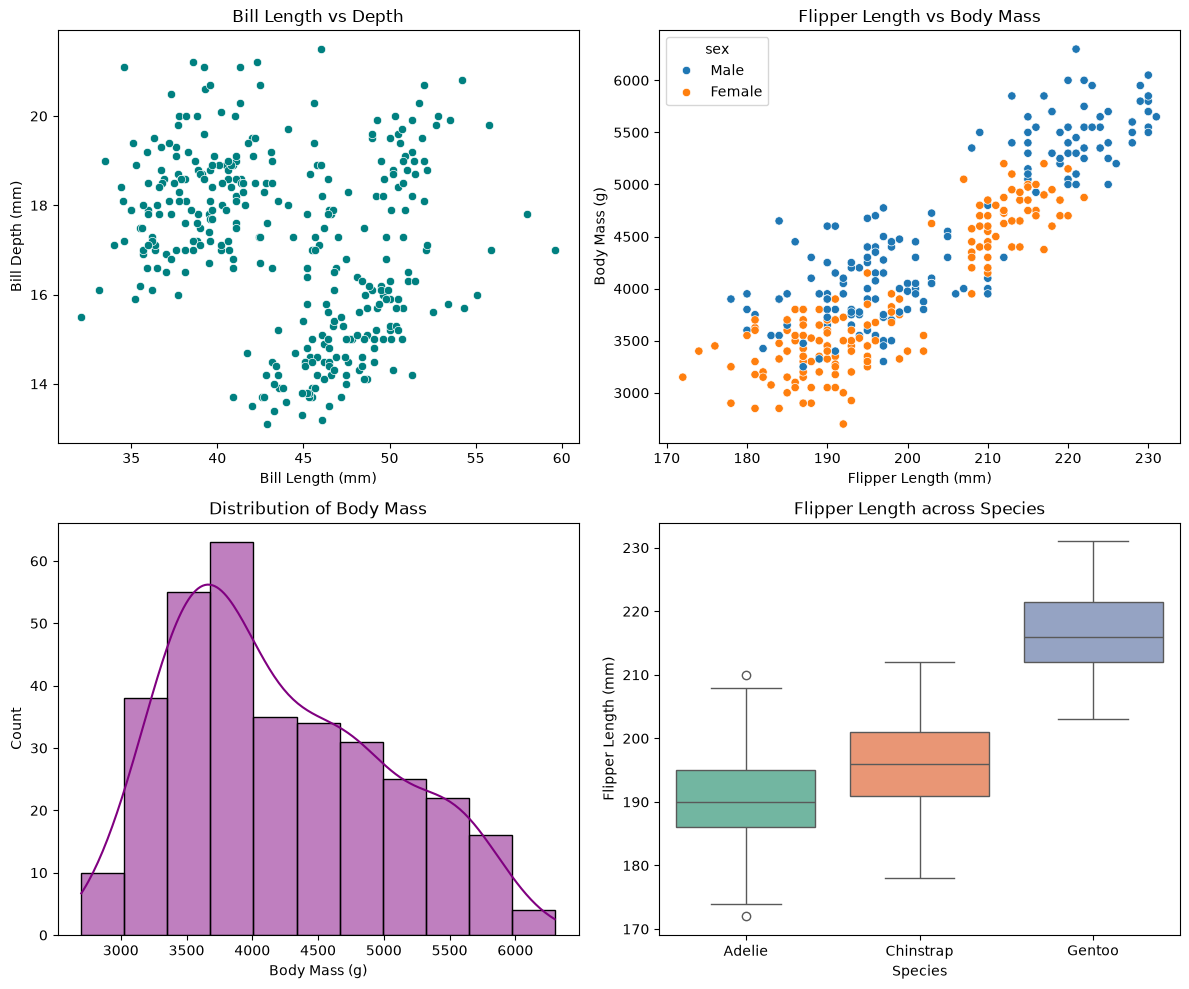

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

sns.scatterplot(data=df_sns, x='bill_length_mm', y='bill_depth_mm', ax=axes[0, 0], color='teal')
axes[0, 0].set_title('Bill Length vs Depth')
axes[0, 0].set_xlabel('Bill Length (mm)')
axes[0, 0].set_ylabel('Bill Depth (mm)')

sns.scatterplot(data=df_sns, x='flipper_length_mm', y='body_mass_g', ax=axes[0, 1], color='coral', hue='sex')
axes[0, 1].set_title('Flipper Length vs Body Mass')
axes[0, 1].set_xlabel('Flipper Length (mm)')
axes[0, 1].set_ylabel('Body Mass (g)')

sns.histplot(data=df_sns, x='body_mass_g', ax=axes[1, 0], color='purple', kde=True)
axes[1, 0].set_title('Distribution of Body Mass')
axes[1, 0].set_xlabel('Body Mass (g)')
axes[1, 0].set_ylabel('Count')

sns.boxplot(data=df_sns, x='species', y='flipper_length_mm', ax=axes[1, 1], hue='species', palette='Set2', legend=False)
axes[1, 1].set_title('Flipper Length across Species')
axes[1, 1].set_xlabel('Species')
axes[1, 1].set_ylabel('Flipper Length (mm)')

plt.tight_layout()
plt.show()
